# Solutions for Week 8 activities: data visualization

# Setup

In [1]:
# packages
import pandas as pd
import numpy as np
import os
from plotnine import *  # may need to install plotnine via pip install or conda install
import matplotlib.pyplot as plt  
import seaborn as sns # may need to install

# print multiple objects from the same cell
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"


Load the datasets

- `childnoinsur_complete.csv`. Store this as `ci`
- `childpov_insur_2324.csv`. Store this as `df` - this is the merged dataset for 2023 and 2024 we created in the previous activity

All data can be found on this page: https://rebeccajohnson88.github.io/PPOL5203_fall2026/datasets.html

In [2]:
ci = pd.read_csv("../datasets/childnoinsur_complete.csv")
df = pd.read_csv("../datasets/childpov_insur_2324.csv")

In [3]:
ci.head()
df.head()

,State,Race,Year,uninsured_rate,Census_Division
0,Wyoming,Non-Hispanic White,2018,0.07,Mountain
1,Wyoming,Hispanic or Latino,2018,0.06,Mountain
2,Wyoming,Black or African American,2018,0.02,Mountain
3,Wyoming,Asian and Pacific Islander,2018,0.02,Mountain
4,Wisconsin,Two or more races,2018,0.02,East North Central


,state,year,race_ethnicity,child_poverty_rate,uninsured_rate,census_division
0,Alabama,2023,American Indian or Alaska Native,NaN,0.04,East South Central
1,Alabama,2023,Asian and Pacific Islander,0.08,NaN,East South Central
2,Alabama,2023,Black or African American,0.41,0.05,East South Central
3,Alabama,2023,Hispanic or Latino,0.27,0.10,East South Central
4,Alabama,2023,Non-Hispanic White,0.11,0.02,East South Central


# Activity 1: continuous data in child uninsurance

A. 

- Subset the child uninsurance data (`ci`) to the year 2024
- Use plotnine to create a histogram of the child uninsurance rate (not separating out by race/ethnicity group) with 20 bins


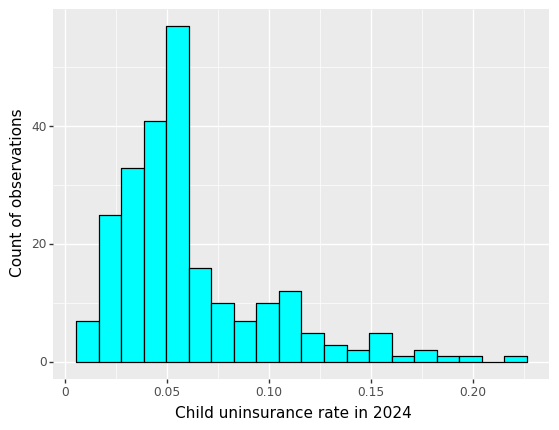

<ggplot: (8767269837975)>

In [4]:
(ggplot(ci[ci.Year == 2024], aes(x = 'uninsured_rate')) +
geom_histogram(color = 'Black', fill = 'cyan', bins = 20) +
ylab('Count of observations') +
xlab('Child uninsurance rate in 2024'))

B. Add a facet_wrap to the plot from part A to create a separate facet for each race/ethnicity group

What do you notice about how the distributions differ across groups?

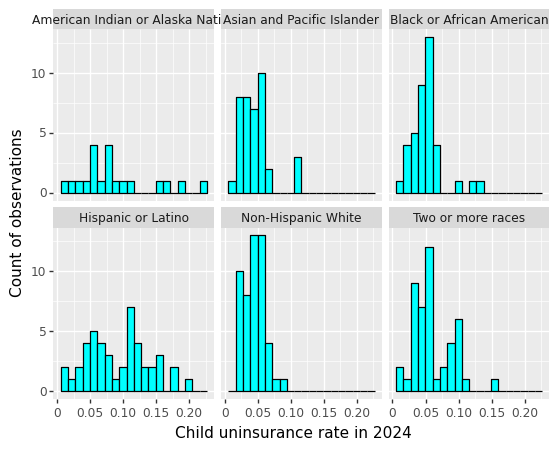

<ggplot: (8767237719444)>

In [5]:
(ggplot(ci[ci.Year == 2024], aes(x = 'uninsured_rate')) +
geom_histogram(color = 'Black', fill = 'cyan', bins = 20) +
ylab('Count of observations') +
xlab('Child uninsurance rate in 2024') +
facet_wrap('~Race'))

C. Create the same plot from part B using `seaborn`; feel free to use generative AI to assist you in translating the code

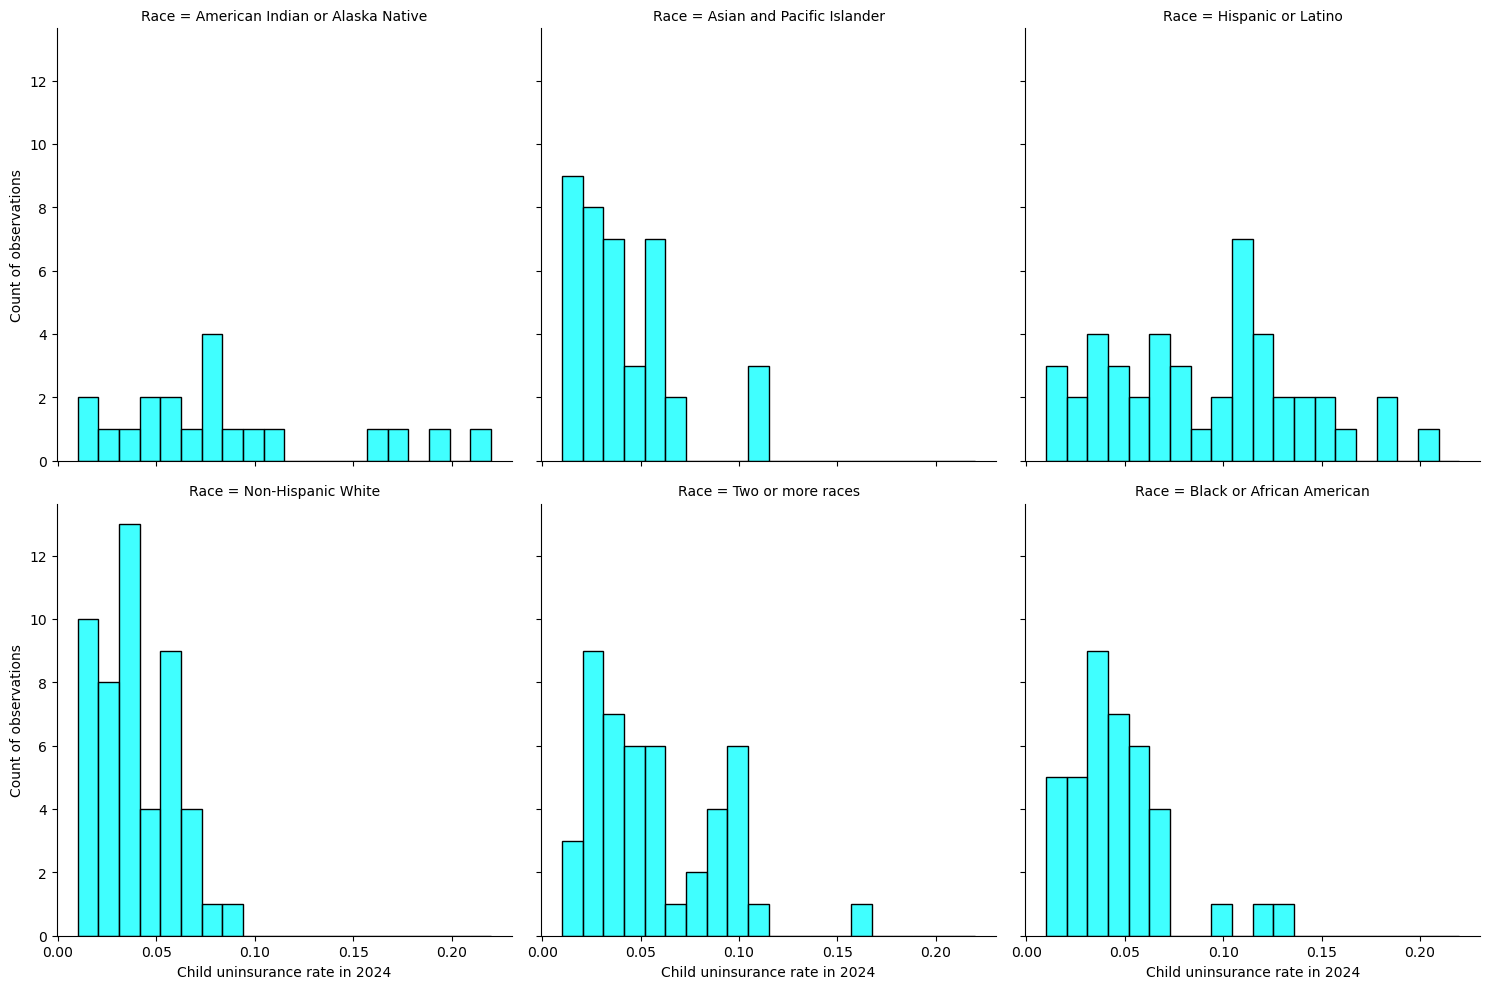

In [6]:
g = sns.displot(data=ci[ci.Year == 2024], x='uninsured_rate',
                 col='Race', col_wrap=3,
                 bins=20, color='cyan', edgecolor='black')

g = g.set_axis_labels('Child uninsurance rate in 2024', 'Count of observations')
plt.show()

# Activity 2: categorical versus continuous in child uninsurance

A. 

- Use the same child uninsurance data subsetted to 2024
- Use a group by / aggregate statement to get the mean uninsurance rate for each race/ethnicity group
- Create a barplot where the x axis is the race/ethnicity group and the y axis is the mean uninsurance rate for that group across states, ordered from highest to lowest uninsurance rate

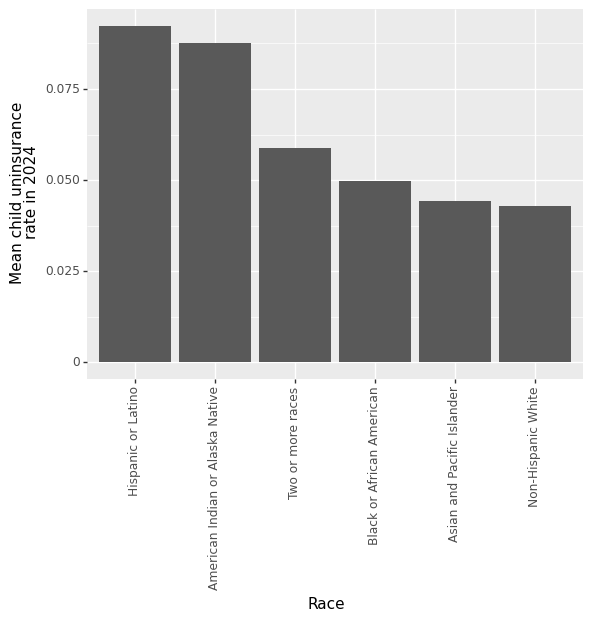

<ggplot: (8767258731021)>

In [7]:
ci_byr = ci[ci.Year == 2024].groupby('Race')['uninsured_rate'].mean().\
                    reset_index().sort_values(by = 'uninsured_rate', ascending = False)
(ggplot(ci_byr, aes(x = 'Race', y = 'uninsured_rate')) +
geom_bar(stat = 'identity') +
ylab("Mean child uninsurance\nrate in 2024") +
scale_x_discrete(limits = ci_byr.Race) +
theme(axis_text_x = element_text(rotation = 90)))

B. 

- Use the same child uninsurance data subsetted to 2024
- Use a group by / aggregate statement to get the mean uninsurance rate by race/ethnicity group WITHIN each Census Division 
- Create a barplot where the x axis is the race/ethnicity group, the y axis is the mean uninsurance rate for that group, and the plot is faceted to show each separate Census Division

/Users/rj545/opt/anaconda3/lib/python3.9/site-packages/plotnine/facets/facet.py:446: PlotnineWarning: If you need more space for the y-axis tick text use ... + theme(subplots_adjust={'hspace': 0.25}). Choose an appropriate value for 'hspace'


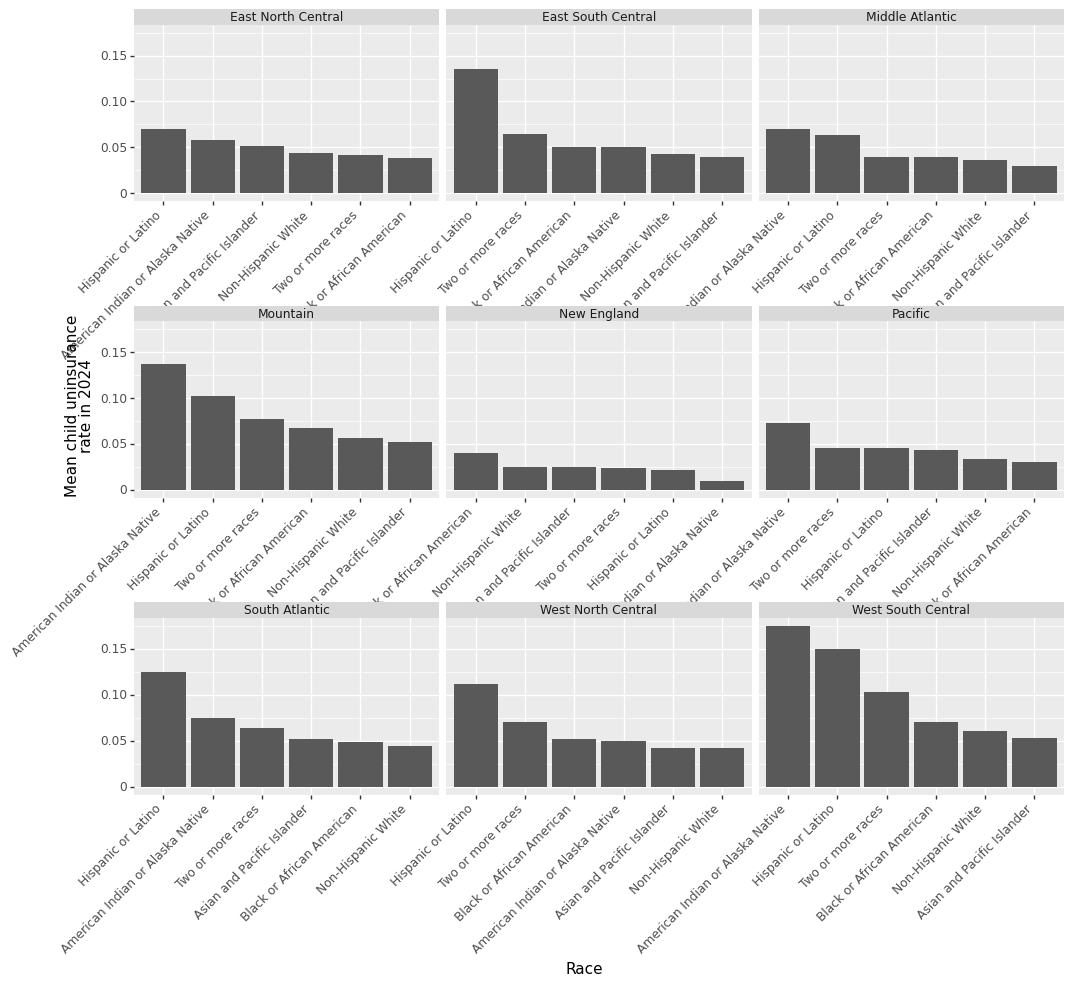

<ggplot: (8767239148063)>

In [17]:
ci_byr_byd = ci[ci.Year == 2024].groupby(['Race', 'Census_Division'])['uninsured_rate'].mean().\
                    reset_index().sort_values(by = 'uninsured_rate', ascending = False)

df = (ci_byr_byd
      .sort_values(['Census_Division', 'uninsured_rate'], ascending=[True, False])
      .copy())

# x variable that's unique per facet, with categories in that sorted order
df['race_div'] = df['Race'] + '___' + df['Census_Division']
df['race_div'] = pd.Categorical(df['race_div'], categories=df['race_div'], ordered=True)

(ggplot(df, aes(x='race_div', y='uninsured_rate')) +
 geom_col() +
 scale_x_discrete(labels=lambda breaks: [b.split('___')[0] for b in breaks]) +
 facet_wrap('~Census_Division', scales='free_x') +
 xlab('Race') +
 ylab("Mean child uninsurance\nrate in 2024") +
 theme(axis_text_x=element_text(rotation=45, ha='right'),
       figure_size=(12, 10),
       panel_spacing_y=1))

C. 

- Return to data from the full panel of years 
- Find the mean child uninsurance rate for each racial/ethnic group and each year
- Create a lineplot where the:
    - x axis is the year 
    - y axis is the mean child uninsurance rate for that year
    - lines connect the years 
    - facet_wrap creates a separate plot for each racial/ethnic group

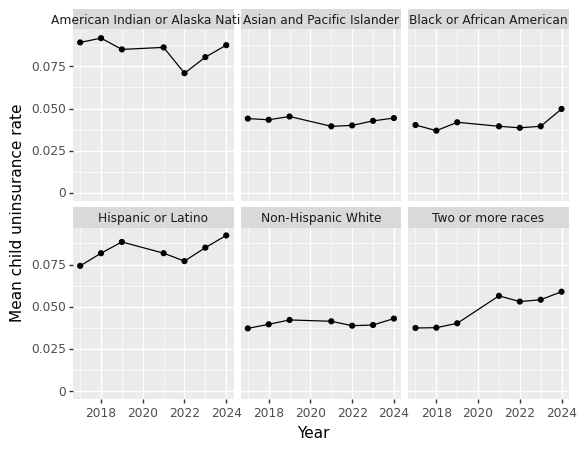

<ggplot: (8767238643706)>

In [10]:
ci_year = ci.groupby(['Race', 'Year'])['uninsured_rate'].mean().\
                    reset_index()

(ggplot(ci_year, aes(x = 'Year', y = 'uninsured_rate')) +
geom_point() +
geom_line() +
ylim(0, np.max(ci_year.uninsured_rate)) +
ylab("Mean child uninsurance rate") +
facet_wrap('~Race'))

# Activity 3: continuous versus continuous 



A. 

- Using `df` (the merged dataset), create a scatterplot where the child poverty rate is on the x axis, the child uninsurance rate is on the y axis, and each dot is a particular state-year-group observation


In [11]:
df.head()

,state,year,race_ethnicity,child_poverty_rate,uninsured_rate,census_division
0,Alabama,2023,American Indian or Alaska Native,NaN,0.04,East South Central
1,Alabama,2023,Asian and Pacific Islander,0.08,NaN,East South Central
2,Alabama,2023,Black or African American,0.41,0.05,East South Central
3,Alabama,2023,Hispanic or Latino,0.27,0.10,East South Central
4,Alabama,2023,Non-Hispanic White,0.11,0.02,East South Central


/Users/rj545/opt/anaconda3/lib/python3.9/site-packages/plotnine/layer.py:411: PlotnineWarning: geom_point : Removed 311 rows containing missing values.


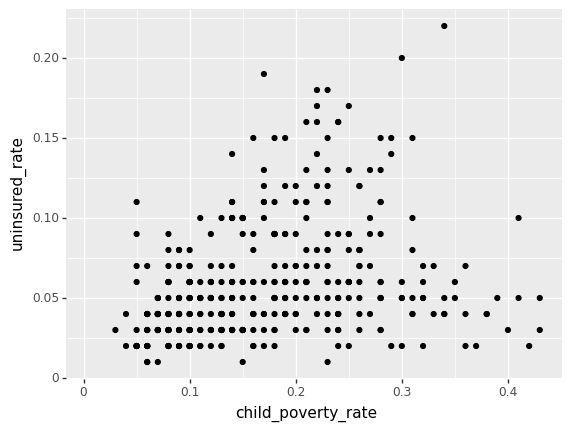

<ggplot: (8767238827533)>

In [12]:
(ggplot(df, aes(x = 'child_poverty_rate', y = 'uninsured_rate')) +
geom_point())

B. Add a smoother to the plot

/Users/rj545/opt/anaconda3/lib/python3.9/site-packages/plotnine/stats/smoothers.py:321: PlotnineWarning: Confidence intervals are not yet implemented for lowess smoothings.
/Users/rj545/opt/anaconda3/lib/python3.9/site-packages/plotnine/layer.py:411: PlotnineWarning: geom_point : Removed 311 rows containing missing values.


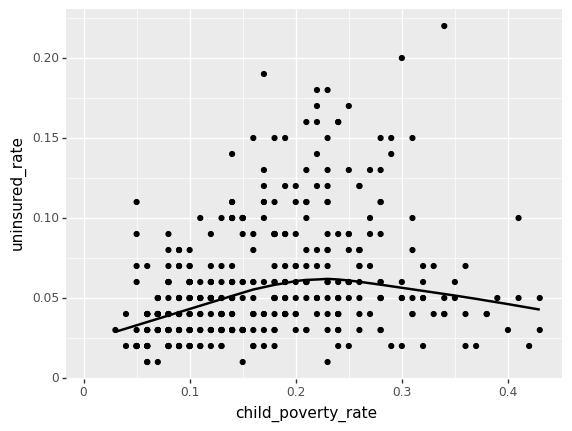

<ggplot: (8767269854952)>

In [13]:
(ggplot(df, aes(x = 'child_poverty_rate', y = 'uninsured_rate')) +
geom_point() +
geom_smooth())

C. Facet by child race/ethnicity 

What patterns and/or data limitations do you notice?

/Users/rj545/opt/anaconda3/lib/python3.9/site-packages/plotnine/stats/smoothers.py:321: PlotnineWarning: Confidence intervals are not yet implemented for lowess smoothings.
/Users/rj545/opt/anaconda3/lib/python3.9/site-packages/plotnine/stats/smoothers.py:321: PlotnineWarning: Confidence intervals are not yet implemented for lowess smoothings.
/Users/rj545/opt/anaconda3/lib/python3.9/site-packages/plotnine/stats/smoothers.py:321: PlotnineWarning: Confidence intervals are not yet implemented for lowess smoothings.
/Users/rj545/opt/anaconda3/lib/python3.9/site-packages/plotnine/stats/smoothers.py:321: PlotnineWarning: Confidence intervals are not yet implemented for lowess smoothings.
/Users/rj545/opt/anaconda3/lib/python3.9/site-packages/plotnine/stats/smoothers.py:321: PlotnineWarning: Confidence intervals are not yet implemented for lowess smoothings.
/Users/rj545/opt/anaconda3/lib/python3.9/site-packages/plotnine/stats/smoothers.py:321: PlotnineWarning: Confidence intervals are not y

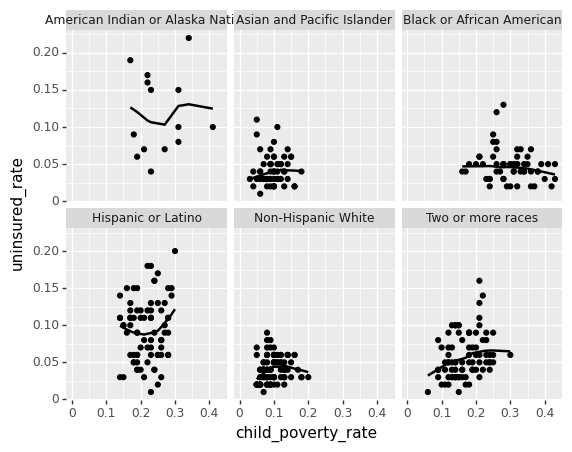

<ggplot: (8767219482603)>

In [14]:
(ggplot(df[df.race_ethnicity != 'Total'],
        aes(x = 'child_poverty_rate', y = 'uninsured_rate')) +
geom_point() +
geom_smooth() +
facet_wrap('~race_ethnicity'))